# Things to consider
1. Importing the required libraries
2. Apply and save the tokenizer later for testing  
4. Apply CNN  
5. Saving the results in a csv file and the model  
6. Show the digrams for AUC, matrix correlation, loss and accuracy of train/test  
7. Apply Bi-directional LSTM  
8. Saving the results in a csv file and the model  
9. Show the digrams for AUC, matrix correlation, loss and accuracy of train/test
10. Apply Bert (Depeding on the variances)
11. **Bert provides different tokenizer**
12. Saving the results in a csv file and the model  
13. Show the digrams for AUC, matrix correlation, loss and accuracy of train/test  

## Start

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np

# Visualizing the results
import matplotlib.pyplot as plt

# Split the data for training and testing
from sklearn.model_selection import train_test_split

# Imbalance dataset
from sklearn.utils.class_weight import compute_class_weight

# Metrics
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
    roc_auc_score, roc_curve, auc,
    precision_recall_curve, average_precision_score,
    precision_score, recall_score, f1_score,
    confusion_matrix, classification_report)

# Tenseflow for CNN and BiLSTM
import tensorflow as tf

# Transformation and padding
from tensorflow.keras.preprocessing import sequence
# from tensorflow.keras.preprocessing.text import Tokenizer, tokenizer_from_json
from tensorflow.keras.preprocessing.sequence import pad_sequences

from sklearn.preprocessing import LabelEncoder

# Tokenizer WordPiece
from transformers import BertTokenizer

# Metrics
from tensorflow.keras.metrics import AUC

# Building the models
from tensorflow.keras.layers import Dense, Flatten, Dropout, Embedding, Input
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, CSVLogger, Callback
from tensorflow.keras.optimizers import AdamW

# CNN
from tensorflow.keras.layers import Conv1D, GlobalMaxPooling1D, Concatenate

# BiLSTM
from tensorflow.keras.layers import LSTM, Masking, Bidirectional, SpatialDropout1D, LayerNormalization
from tensorflow.keras.utils import to_categorical, plot_model

# Load and Save Model
from tensorflow.keras.models import load_model, save_model

# Used to calculate the training time
from time import perf_counter

from tensorflow.keras.preprocessing.text import tokenizer_from_json
import json

np.random.seed(42)
tf.random.set_seed(42)

%matplotlib inline

## Importing the data

In [ ]:
# 1. Baseline -
# 2. Cleaned -
# 3. NER -
# Datasets:
# Enron - Done
# SpamAssassin - Done
# LingSpam -
abstract = "NER"
name = "LingSpam"

In [ ]:
df = pd.read_csv(f'drive/MyDrive/Dissertation/Datasets/{abstract}/{name}/{name}_{abstract}.csv')

In [ ]:
# Fix the print
before = len(df)
df = df.drop_duplicates(subset=['text']).reset_index(drop=True)
after = len(df)
print(f"Before dedup: {before}")
print(f"After dedup: {after}")
print(f"Removed: {before - after} rows")

Before dedup: 2893
After dedup: 2859
Removed: 34 rows


In [ ]:
df.columns, df.shape

(Index(['text', 'label', 'expanded_text', 'processed_text'], dtype='object'),
 (2859, 4))

In [ ]:
X = df["text"] if abstract == "Baseline" else df['processed_text'] # df['text']
y = df['label']

In [ ]:
# We will split the dataset into 70/10/20, to keep consistent with the ML models testing model.
# First split: Training 80%, Test 20%
X_train80, X_test, y_train80, y_test = train_test_split(
    X, y, test_size=0.2,
    stratify=y, random_state=42)

# Caculation the validation from the training split
# val_percent = V / (1 - T)
# where V is the validation percent that is required, while T is the test percentage
# V = 10%, T = 20%, our val_percent is 10/80 = 0.125 * 100% = 12.5%
val_percent = 0.10/(1-0.2)

X_train70, X_val, y_train70, y_val = train_test_split(
    X_train80, y_train80, test_size=val_percent,
    stratify=y_train80, random_state=42)

In [ ]:
print(f"Total: {len(df)}")
print(f"Train: {len(X_train70)}")
print(f"Val: {len(X_val)}")

Total: 2859
Train: 2001
Val: 286


In [ ]:
# Convert y_train to float32
y_train70_float = y_train70.astype('float32')

# Convert y_val to float32
y_val_float = y_val.astype('float32')

# Convert y_test to float32
y_test_float = y_test.astype('float32')

## WordPiece Tokenizer

In [ ]:
def show_class_balance(y, name):
    counts = pd.Series(y).value_counts(normalize=True)
    print(f"{name} distribution:")
    print(counts)
    print()

show_class_balance(y_train70_float, "Train")
show_class_balance(y_val_float, "Validation")
show_class_balance(y_test_float, "Test")

Train distribution:
label
0.0    0.84008
1.0    0.15992
Name: proportion, dtype: float64

Validation distribution:
label
0.0    0.839161
1.0    0.160839
Name: proportion, dtype: float64

Test distribution:
label
0.0    0.839161
1.0    0.160839
Name: proportion, dtype: float64



In [ ]:
# 1. Load the pre-trained tokenizer (same one BERT uses)
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

# Definig custom tokens
custom_ner_tokens : list[str] = [
    "EMAILNER",
    "PHONENER",
    "WEBNER",
    "DATENER",
    "TIMENER",
    "MONEYNER",
    "PERCENTNER",
    "PERNER",
    "ORGNER",
    "GPENER",
    "LOCNER",
    "PRODUCTNER",
    "EVENTNER",
    "NORPNER",
    "LANGNER",
    "NUMNER",
]

# Register to the tokenizer treating them as a single unit
tokenizer.add_special_tokens({"additional_special_tokens": custom_ner_tokens})

tokenizer.save_pretrained(f'drive/MyDrive/Dissertation/Results/{abstract}/{name}/Features/Keras_Tokenizer')

# 2. Tokenize each split independently — no fitting, no leakage
def encode(texts):
    return tokenizer(
        texts.tolist(),
        padding='max_length',
        truncation=True,
        max_length=512,
        return_tensors='np'
    )

train_enc = encode(X_train70)
val_enc   = encode(X_val)
test_enc  = encode(X_test)

# 3. Extract input IDs for Keras (CNN / BiLSTM)
X_train_tok = train_enc['input_ids']   # shape: (n_samples, 512)
X_val_tok   = val_enc['input_ids']
X_test_tok  = test_enc['input_ids']

print("Shape:", X_train_tok.shape)  # (n_samples, 512)
print("Type:", type(X_train_tok))

Shape: (2001, 512)
Type: <class 'numpy.ndarray'>


## Fixing class imbalance

In [ ]:
# Fixing the class imbalance
classes = np.unique(y_train70_float)

cw = compute_class_weight('balanced', classes=classes, y=y_train70_float)
class_weights = {int(k): float(v) for k, v in zip(classes, cw)}

pos_weight_scalar = float(class_weights[1] / class_weights[0])
print("== Class weight for spam and ham ==")

print(class_weights)
print(f"pos_weight for DL/Transformers: {pos_weight_scalar:.4f}")

== Class weight for spam and ham ==
{0: 0.5951814396192743, 1: 3.1265625}
pos_weight for DL/Transformers: 5.2531


In [ ]:
"""## Custom weighted BCE loss (matches Transformer)"""

def make_weighted_bce(pos_weight):
    def weighted_bce(y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        # Ensure same shape as logits
        loss = tf.nn.weighted_cross_entropy_with_logits(
                labels=y_true, logits=y_pred, pos_weight=pos_weight
            )
        return tf.reduce_mean(loss)
    return weighted_bce

## Callbacks for CNN and BiLSTM

In [ ]:
# Training time for CNN and BiLSTM
class TrainTimer(Callback):
  def on_train_begin(self, logs=None):
    self._t0 = perf_counter()
  def on_train_end(self, logs=None):
    self.total_seconds = perf_counter() - self._t0

In [ ]:
# Logger for CNN and BiLSTM
cnn_logger = CSVLogger(f"drive/MyDrive/Dissertation/Results/{abstract}/{name}/Features/CNN_log", separator=",", append=False)
bilstm_logger = CSVLogger(f"drive/MyDrive/Dissertation/Results/{abstract}/{name}/Features/BiLSTM_log", separator=",", append=False)

# Calculating the total training time
timer_callback = TrainTimer()

callbacks_CNN_tokenization = [
    EarlyStopping(patience=3, monitor='val_pr_auc', mode='max', restore_best_weights=True),
    ModelCheckpoint(f'drive/MyDrive/Dissertation/Results/{abstract}/{name}/Predicted/CNN_model.keras', save_best_only=True, monitor='val_pr_auc', mode='max'),
    cnn_logger,
    timer_callback,
]

callbacks_BiLSTM_tokenization = [
    EarlyStopping(patience=3, monitor='val_pr_auc', mode='max', restore_best_weights=True),
    ModelCheckpoint(f'drive/MyDrive/Dissertation/Results/{abstract}/{name}/Predicted/BiLSTM_model.keras', save_best_only=True,  monitor='val_pr_auc', mode='max'),
    bilstm_logger,
    timer_callback,
]

## CNN

In [ ]:
X_train_CNN  = X_train_tok.copy()
y_train_CNN  = y_train70_float.copy()
X_val_CNN    = X_val_tok.copy()
y_val_CNN    = y_val_float.copy()
X_test_CNN   = X_test_tok.copy()
y_test_CNN   = y_test_float.copy()

In [ ]:
input_sequence = Input(shape=(512,), dtype='int32') # max_sequence_length

embedding = Embedding(
    input_dim= len(tokenizer), # len(word_index) + 1, # +1 for padding token
    output_dim=128
)(input_sequence)

x = SpatialDropout1D(0.2)(embedding)

conv1 = GlobalMaxPooling1D()(Conv1D(filters=128, kernel_size=2, activation='relu', padding='valid')(x))
conv2 = GlobalMaxPooling1D()(Conv1D(filters=128, kernel_size=3, activation='relu', padding='valid')(x))
conv3 = GlobalMaxPooling1D()(Conv1D(filters=128, kernel_size=4, activation='relu', padding='valid')(x))

merge = Concatenate()([conv1, conv2, conv3])
dense1 = Dense(256, activation='relu')(merge)
drop1 = Dropout(0.5)(dense1)
output = Dense(1)(drop1)

model_cnn_tokenizer = Model(inputs=input_sequence, outputs=output)

In [ ]:
model_cnn_tokenizer.compile(
    optimizer=AdamW(2e-5, weight_decay=0.01),
    loss=make_weighted_bce(pos_weight_scalar),
    metrics=['accuracy', AUC(curve='PR', name='pr_auc', from_logits=True)])

history_cnn = model_cnn_tokenizer.fit(
    X_train_CNN, y_train_CNN.values,
    epochs=50, batch_size=32,
    validation_data=(X_val_CNN, y_val_CNN.values),
    callbacks=callbacks_CNN_tokenization,
    verbose=2)

Epoch 1/50
63/63 - 16s - 260ms/step - accuracy: 0.8401 - loss: 1.1627 - pr_auc: 0.1757 - val_accuracy: 0.8392 - val_loss: 1.1627 - val_pr_auc: 0.2784
Epoch 2/50
63/63 - 1s - 10ms/step - accuracy: 0.8401 - loss: 1.1571 - pr_auc: 0.1908 - val_accuracy: 0.8392 - val_loss: 1.1580 - val_pr_auc: 0.5547
Epoch 3/50
63/63 - 1s - 10ms/step - accuracy: 0.8401 - loss: 1.1576 - pr_auc: 0.1947 - val_accuracy: 0.8392 - val_loss: 1.1529 - val_pr_auc: 0.7451
Epoch 4/50
63/63 - 1s - 10ms/step - accuracy: 0.8401 - loss: 1.1500 - pr_auc: 0.2285 - val_accuracy: 0.8392 - val_loss: 1.1472 - val_pr_auc: 0.8686
Epoch 5/50
63/63 - 1s - 11ms/step - accuracy: 0.8401 - loss: 1.1427 - pr_auc: 0.2773 - val_accuracy: 0.8392 - val_loss: 1.1407 - val_pr_auc: 0.9246
Epoch 6/50
63/63 - 1s - 11ms/step - accuracy: 0.8401 - loss: 1.1390 - pr_auc: 0.2845 - val_accuracy: 0.8392 - val_loss: 1.1329 - val_pr_auc: 0.9495
Epoch 7/50
63/63 - 1s - 10ms/step - accuracy: 0.8401 - loss: 1.1328 - pr_auc: 0.3582 - val_accuracy: 0.8392 - 

In [ ]:
print(f"Total training time: {timer_callback.total_seconds/60:.2f} min")

Total training time: 0.39 min


In [ ]:
model_cnn_tokenizer.summary()

Model: "functional_16"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_16      │ (None, 512)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_16        │ (None, 512, 128)  │  3,908,864 │ input_layer_16[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d_… │ (None, 512, 128)  │          0 │ embedding_16[0][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_24 (Conv1D)  │ (None, 511, 128)  │     32,896 │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_25 (Conv1D)  │ (None, 510, 128)  │     49,280 │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_26 (Conv1D)  │ (None, 509, 128)  │     65,664 │ spatial_dropout1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_24[0][0]   │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_25[0][0]   │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_26[0][0]   │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_8       │ (None, 384)       │          0 │ global_max_pooli… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
│                     │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_24 (Dense)    │ (None, 256)       │     98,560 │ concatenate_8[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 256)       │          0 │ dense_24[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_25 (Dense)    │ (None, 1)         │        257 │ dropout_8[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 12,466,565 (47.56 MB)

 Trainable params: 4,155,521 (15.85 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,311,044 (31.70 MB)

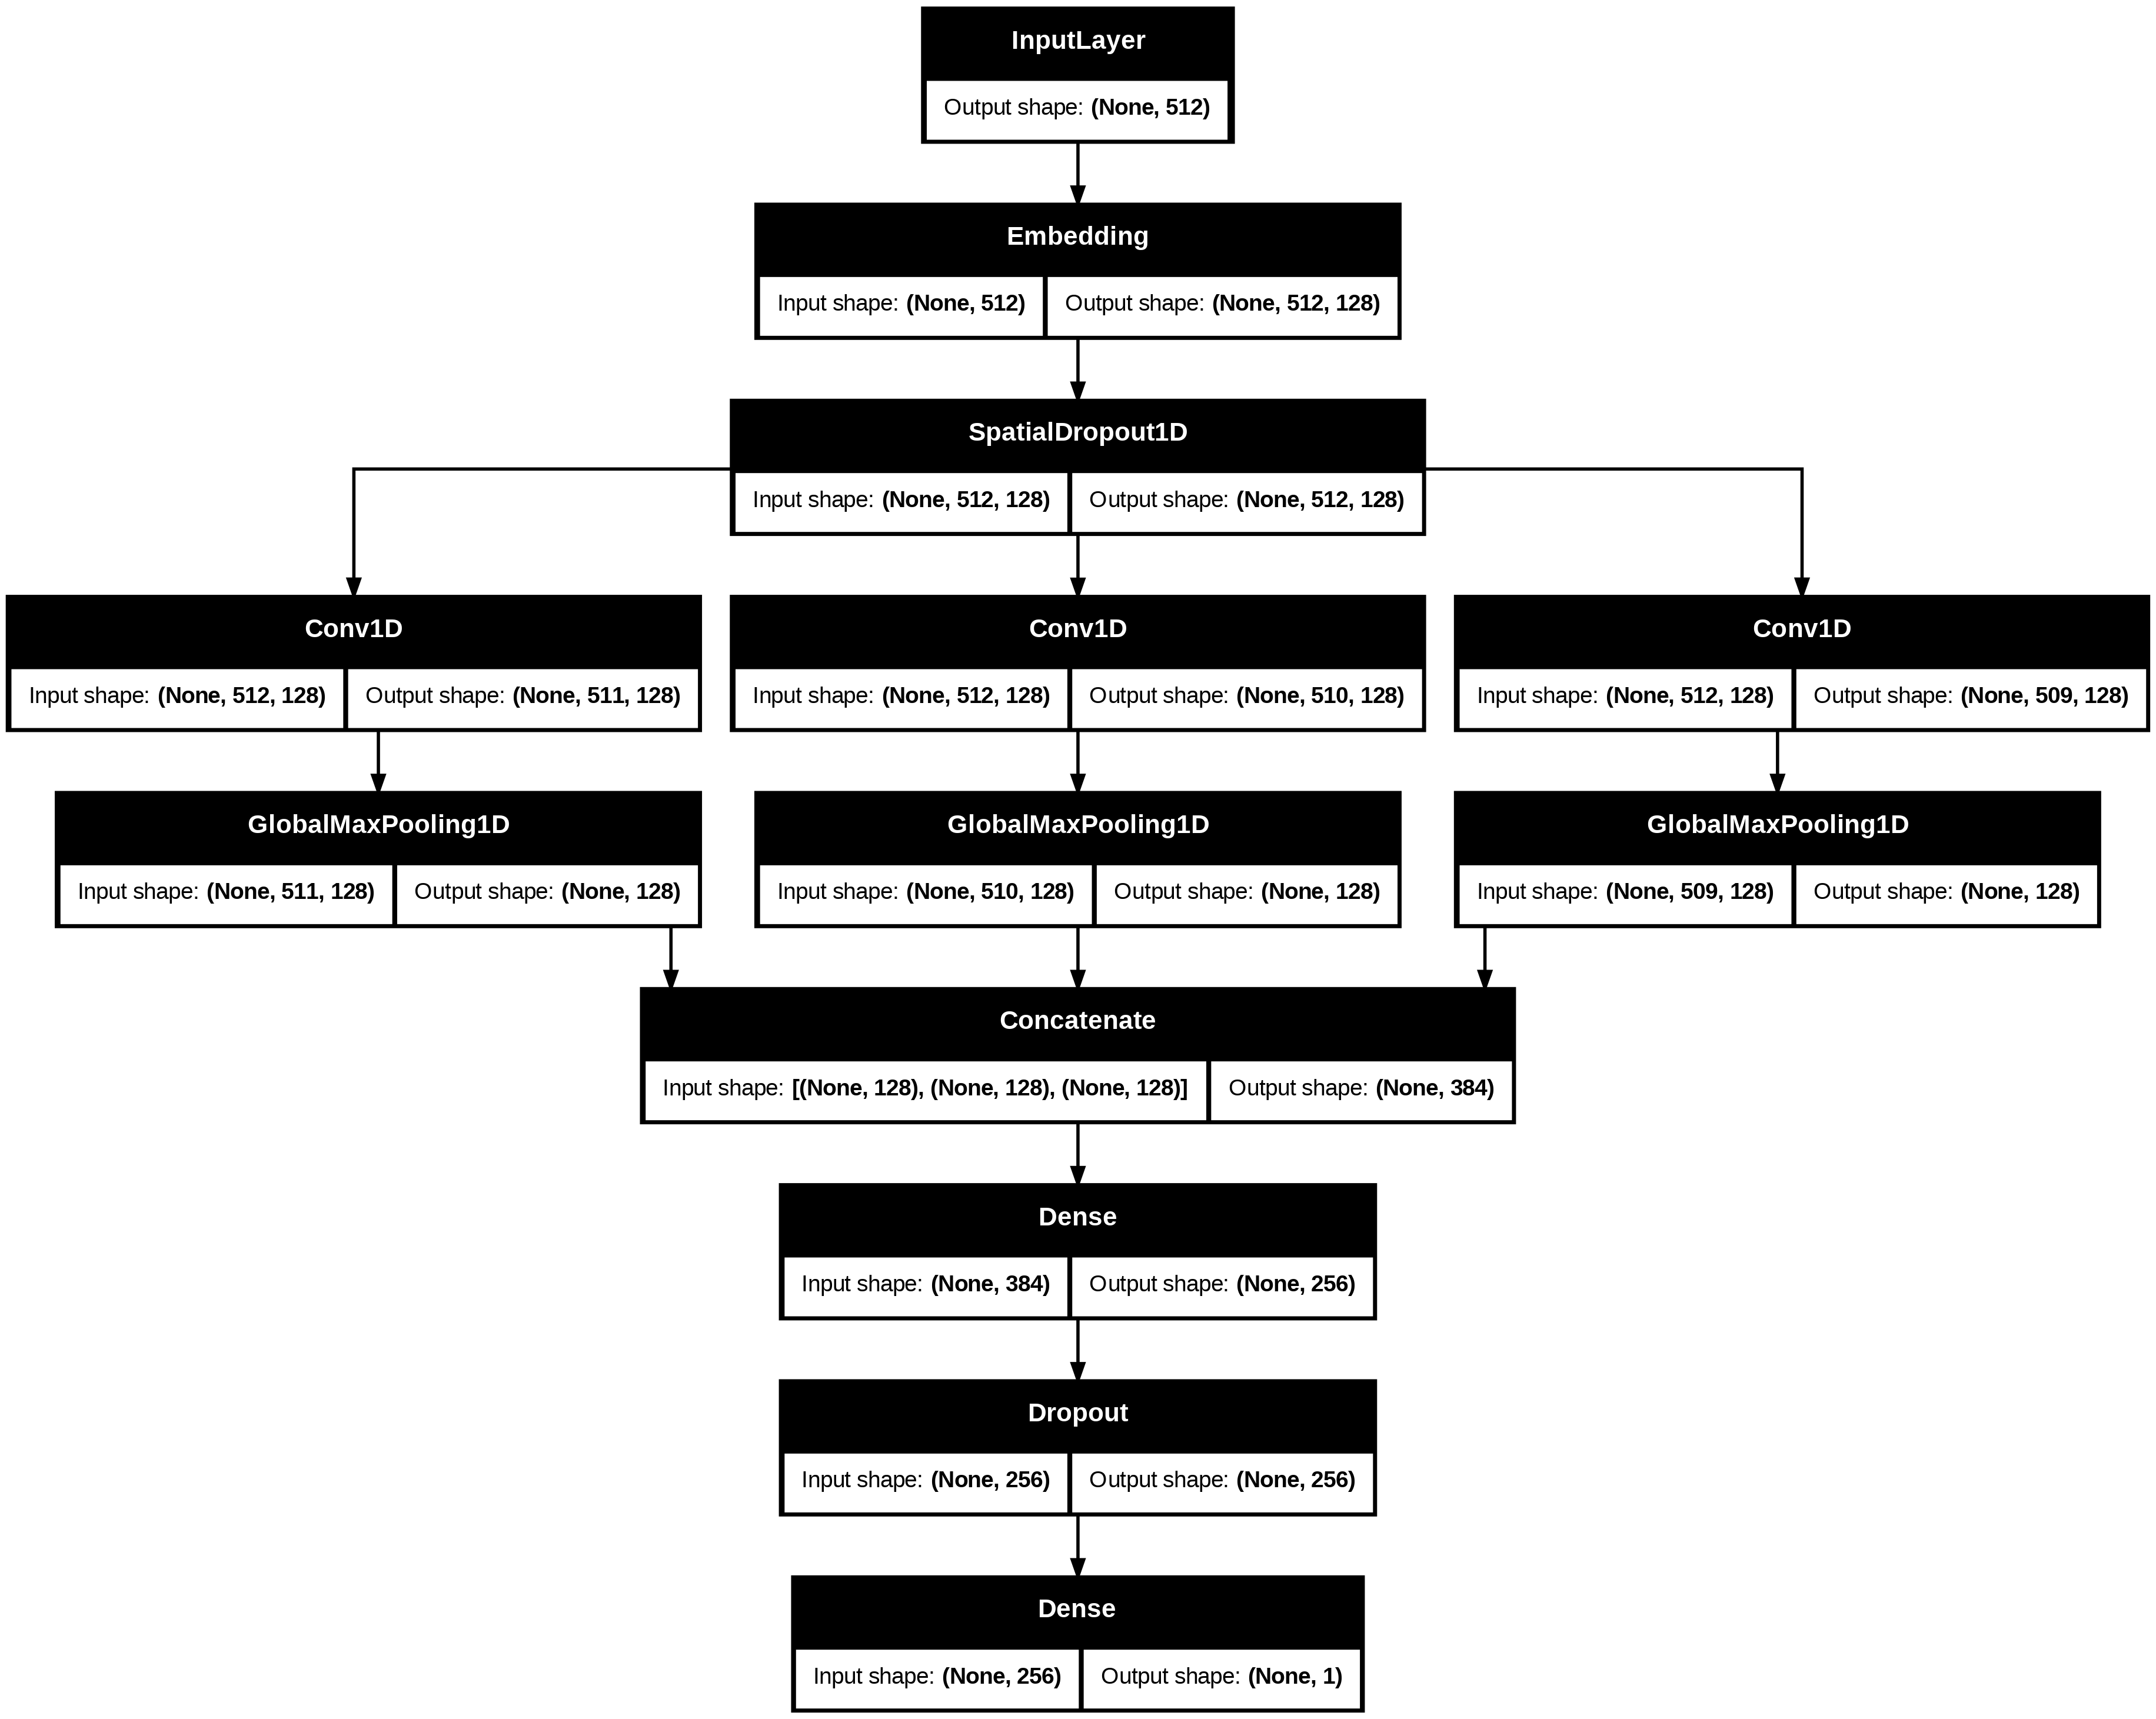

In [ ]:
plot_model(model_cnn_tokenizer, show_shapes=True, to_file=f'drive/MyDrive/Dissertation/Results/{abstract}/{name}/Image/Deep Learning/CNN_multichannel.png')

In [ ]:
# 1. Get RAW LOGITS from model
y_val_logits = model_cnn_tokenizer.predict(X_val_CNN).ravel()

# 2. Convert to PROBABILITIES for sklearn metrics
y_val_probs = tf.nn.sigmoid(y_val_logits).numpy()

# 1. Get precision, recall, and thresholds
precision, recall, thresholds = precision_recall_curve(y_val_CNN, y_val_probs)

# 2. Calculate F1-score for each threshold
# F1 = 2 * (precision * recall) / (precision + recall)
f1_scores = (2 * recall * precision) / (recall + precision + 1e-10)

# 3. Find the index of the highest F1-score
best_idx = np.argmax(f1_scores[:-1])
best_threshold = thresholds[best_idx]

print(f"Best Threshold: {best_threshold:.4f}")
print(f"Best F1-Score: {f1_scores[best_idx]:.4f}")
print(f"Predictions generated using {best_threshold:.4f} threshold.")

# y_val_pred = (y_val_probs >= best_threshold).astype(int)

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 89ms/step
Best Threshold: 0.4998
Best F1-Score: 0.9574
Predictions generated using 0.4998 threshold.


In [ ]:
y_test_logits = model_cnn_tokenizer.predict(X_test_CNN).ravel()
y_test_probs = tf.nn.sigmoid(y_test_logits).numpy()
y_test_pred = (y_test_probs >= best_threshold).astype(int)

# y_val_CNN -> y_test_CNN
# y_val_pred -> y_test_pred

18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step


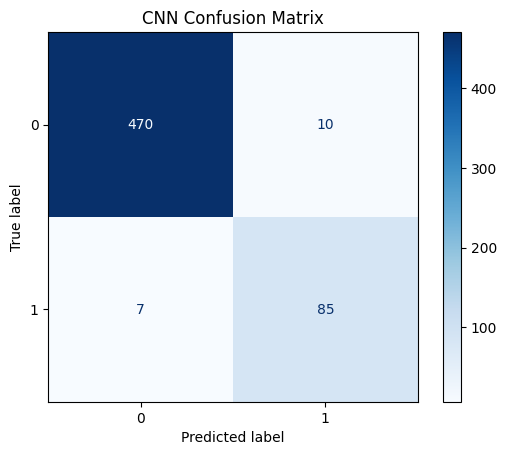

In [ ]:
cm = confusion_matrix(y_test_CNN.values, y_test_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title(f"CNN Confusion Matrix")
plt.savefig(fname=f'drive/MyDrive/Dissertation/Results/{abstract}/{name}/Image/Deep Learning/CNN_confusionMatrix.png', format='png')

In [ ]:
names: list   = ['Ham', 'Spam']
report_cnn = classification_report(y_test_CNN, y_test_pred, target_names=names, output_dict=True)
dataframe_report_cnn = pd.DataFrame(report_cnn).transpose()
dataframe_report_cnn

,precision,recall,f1-score,support
Ham,0.985325,0.979167,0.982236,480.00000
Spam,0.894737,0.923913,0.909091,92.00000
accuracy,0.970280,0.970280,0.970280,0.97028
macro avg,0.940031,0.951540,0.945664,572.00000
weighted avg,0.970755,0.970280,0.970472,572.00000


In [ ]:
# Save the classification report to a CSV file
dataframe_report_cnn.to_csv(f'drive/MyDrive/Dissertation/Results/{abstract}/{name}/Results/classification_report_CNN.csv', index=True)

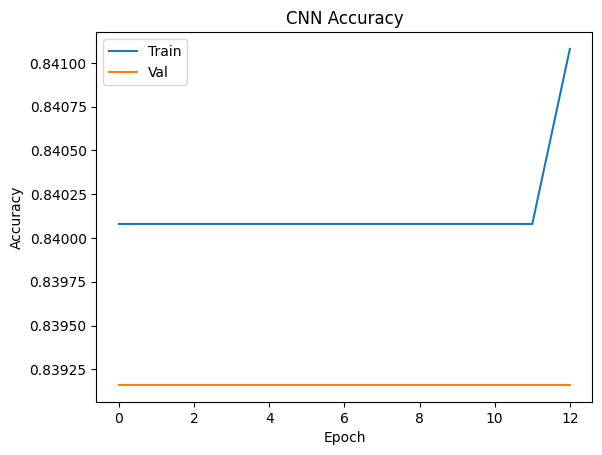

In [ ]:
# summarize history for accuracy
plt.plot(history_cnn.history['accuracy'])
plt.plot(history_cnn.history['val_accuracy'])
plt.title('CNN Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Val'], loc='upper left')
# plt.show()
plt.savefig(f'drive/MyDrive/Dissertation/Results/{abstract}/{name}/Image/Deep Learning/CNN_accuracy.png', format='png')

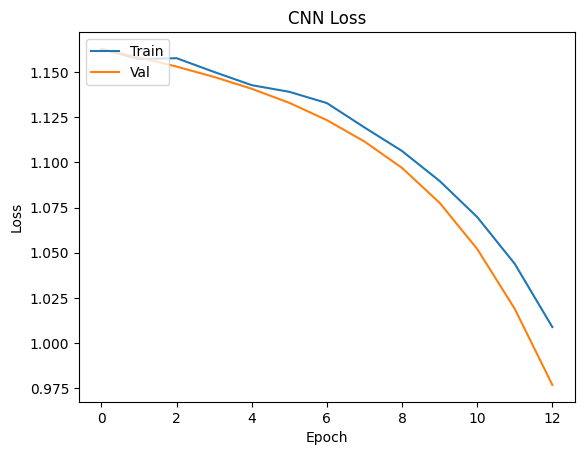

In [ ]:
plt.plot(history_cnn.history['loss'])
plt.plot(history_cnn.history['val_loss'])
plt.title('CNN Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Val'], loc='upper left')
plt.savefig(f'drive/MyDrive/Dissertation/Results/{abstract}/{name}/Image/Deep Learning/CNN_loss.png', format='png')
# plt.show()

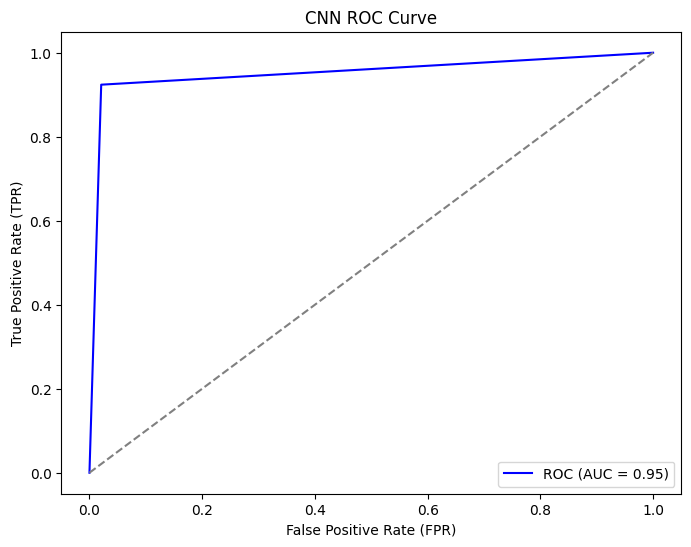

In [ ]:
# AUC SCORE
auc_score = roc_auc_score(y_test_CNN, y_test_pred)

# ROC curve (for plotting)
fpr, tpr, _ = roc_curve(y_test_CNN, y_test_pred)
roc_auc = auc(fpr, tpr)

# Plotting the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f'ROC (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Diagonal line (random classifier)
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title(f'CNN ROC Curve')
plt.legend(loc='lower right')
plt.savefig(fname=f'drive/MyDrive/Dissertation/Results/{abstract}/{name}/Image/Deep Learning/CNN_roc.png', format='png', dpi=300, bbox_inches="tight")

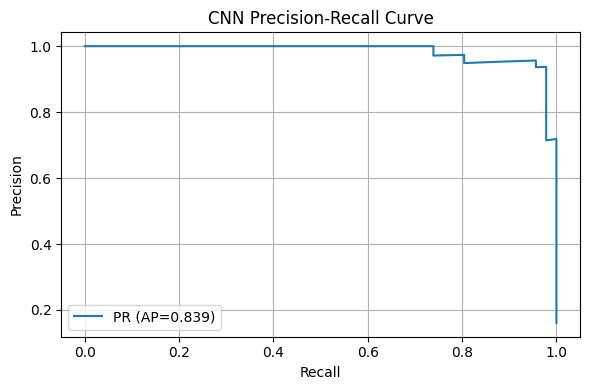

In [ ]:
plt.figure(figsize=(6,4))

ap = np.round(average_precision_score(y_test_CNN, y_test_pred), 3)  # PR-AUC
plt.plot(recall, precision, label=f"PR (AP={ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("CNN Precision-Recall Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(f'drive/MyDrive/Dissertation/Results/{abstract}/{name}/Image/Deep Learning/CNN_pr.png', format='png',  dpi=300, bbox_inches="tight")
# plt.show()

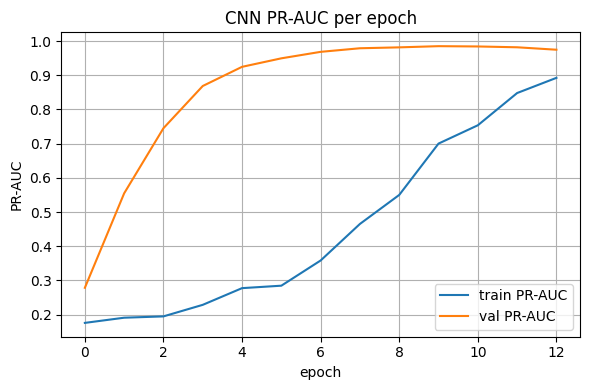

In [ ]:
plt.figure(figsize=(6,4))
plt.plot(history_cnn.history['pr_auc'], label='train PR-AUC')
plt.plot(history_cnn.history['val_pr_auc'], label='val PR-AUC')
plt.xlabel("epoch")
plt.ylabel("PR-AUC")
plt.title("CNN PR-AUC per epoch")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(f'drive/MyDrive/Dissertation/Results/{abstract}/{name}/Image/Deep Learning/CNN_auc.png', format='png')
# plt.show()

In [ ]:
# Calculate metrics
accuracy = np.round(accuracy_score(y_test_CNN, y_test_pred), 3)
precision = np.round(precision_score(y_test_CNN, y_test_pred), 3)
recall = np.round(recall_score(y_test_CNN, y_test_pred), 3)
f1 = np.round(f1_score(y_test_CNN, y_test_pred), 3)
threshold = np.round(best_threshold, 3)

# Confusion Matrix for TP, TN, FP, FN
cm = confusion_matrix(y_test_CNN, y_test_pred)
# Verify label ordering before ravel
print("Confusion matrix:\n", cm)
print("Class distribution:", np.bincount(y_test_CNN.astype(int)))

# sklearn default: rows = true, columns = pred
# [[TN, FP],
#  [FN, TP]]
tn, fp, fn, tp = cm.ravel()  # Extracting true negative, false positive, false negative, true positive

print("==CNN Metrics==")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)
print()
print("True Positive:", tp)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Negative:", tn)

Confusion matrix:
 [[470  10]
 [  7  85]]
Class distribution: [480  92]
==CNN Metrics==
Accuracy: 0.97
Precision: 0.895
Recall: 0.924
F1-Score: 0.909

True Positive: 85
False Positive: 10
False Negative: 7
True Negative: 470


In [ ]:
results_dp = pd.DataFrame(columns=['Model','Time','Accuracy','Precision','Recall',
                           'F1-Score', 'Threshold', 'AUC', 'PR-AUC', 'TP','TN','FP','FN'])

In [ ]:
results_dp.loc[len(results_dp)] = ["CNN",
                   round(timer_callback.total_seconds/60, 2),
                   accuracy, precision, recall, f1, threshold, auc_score,
                   ap, tp, tn, fp, fn]

In [ ]:
results_dp

,Model,Time,Accuracy,Precision,Recall,F1-Score,Threshold,AUC,PR-AUC,TP,TN,FP,FN
0,CNN,0.39,0.97,0.895,0.924,0.909,0.5,0.95154,0.839,85,470,10,7


## BiLSTM

In [ ]:
X_train_BILSTM = X_train_tok.copy()
y_train_BILSTM = y_train70_float.copy()
X_val_BILSTM   = X_val_tok.copy()
y_val_BILSTM   = y_val_float.copy()
X_test_BILSTM  = X_test_tok.copy()
y_test_BILSTM  = y_test_float.copy()

In [ ]:
model_lstm_vect = Sequential([
    Input(shape=(512,), dtype='int32'),

    Embedding(
        input_dim= len(tokenizer), #len(word_index) + 1,
        output_dim=128
    ),

    SpatialDropout1D(0.2),
    Bidirectional(LSTM(128, return_sequences=True)),
    LayerNormalization(),
    Bidirectional(LSTM(128, return_sequences=False)),
    LayerNormalization(),
    Dense(1)
])

In [ ]:
model_lstm_vect.compile(optimizer=AdamW(2e-5, weight_decay=0.01),
                        loss=make_weighted_bce(pos_weight_scalar),
                        metrics=['accuracy', AUC(curve='PR', name='pr_auc', from_logits=True)])

history_lstm = model_lstm_vect.fit(
    X_train_BILSTM, y_train_BILSTM.values,
    epochs=50, batch_size=32,
    validation_data=(X_val_BILSTM, y_val_BILSTM.values),
    callbacks=callbacks_BiLSTM_tokenization,
    verbose=2)

Epoch 1/50
63/63 - 13s - 207ms/step - accuracy: 0.7186 - loss: 1.1834 - pr_auc: 0.2456 - val_accuracy: 0.8112 - val_loss: 1.0053 - val_pr_auc: 0.4819
Epoch 2/50
63/63 - 5s - 81ms/step - accuracy: 0.8141 - loss: 0.9229 - pr_auc: 0.4722 - val_accuracy: 0.8671 - val_loss: 0.8054 - val_pr_auc: 0.6571
Epoch 3/50
63/63 - 5s - 80ms/step - accuracy: 0.8731 - loss: 0.7325 - pr_auc: 0.6496 - val_accuracy: 0.8986 - val_loss: 0.6560 - val_pr_auc: 0.7453
Epoch 4/50
63/63 - 5s - 80ms/step - accuracy: 0.9055 - loss: 0.5736 - pr_auc: 0.7908 - val_accuracy: 0.9091 - val_loss: 0.5252 - val_pr_auc: 0.8269
Epoch 5/50
63/63 - 5s - 80ms/step - accuracy: 0.9195 - loss: 0.4523 - pr_auc: 0.8453 - val_accuracy: 0.9266 - val_loss: 0.4495 - val_pr_auc: 0.8665
Epoch 6/50
63/63 - 6s - 92ms/step - accuracy: 0.9390 - loss: 0.3504 - pr_auc: 0.9102 - val_accuracy: 0.9301 - val_loss: 0.3883 - val_pr_auc: 0.8989
Epoch 7/50
63/63 - 5s - 81ms/step - accuracy: 0.9455 - loss: 0.2884 - pr_auc: 0.9310 - val_accuracy: 0.9266 - 

In [ ]:
model_lstm_vect.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_17 (Embedding)        │ (None, 512, 128)       │     3,908,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_17            │ (None, 512, 128)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_16                │ (None, 512, 256)       │       263,168 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_16          │ (None, 512, 256)       │           512 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_17                │ (None, 256)            │       394,240 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_17          │ (None, 256)            │           512 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,702,661 (52.27 MB)

 Trainable params: 4,567,553 (17.42 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 9,135,108 (34.85 MB)

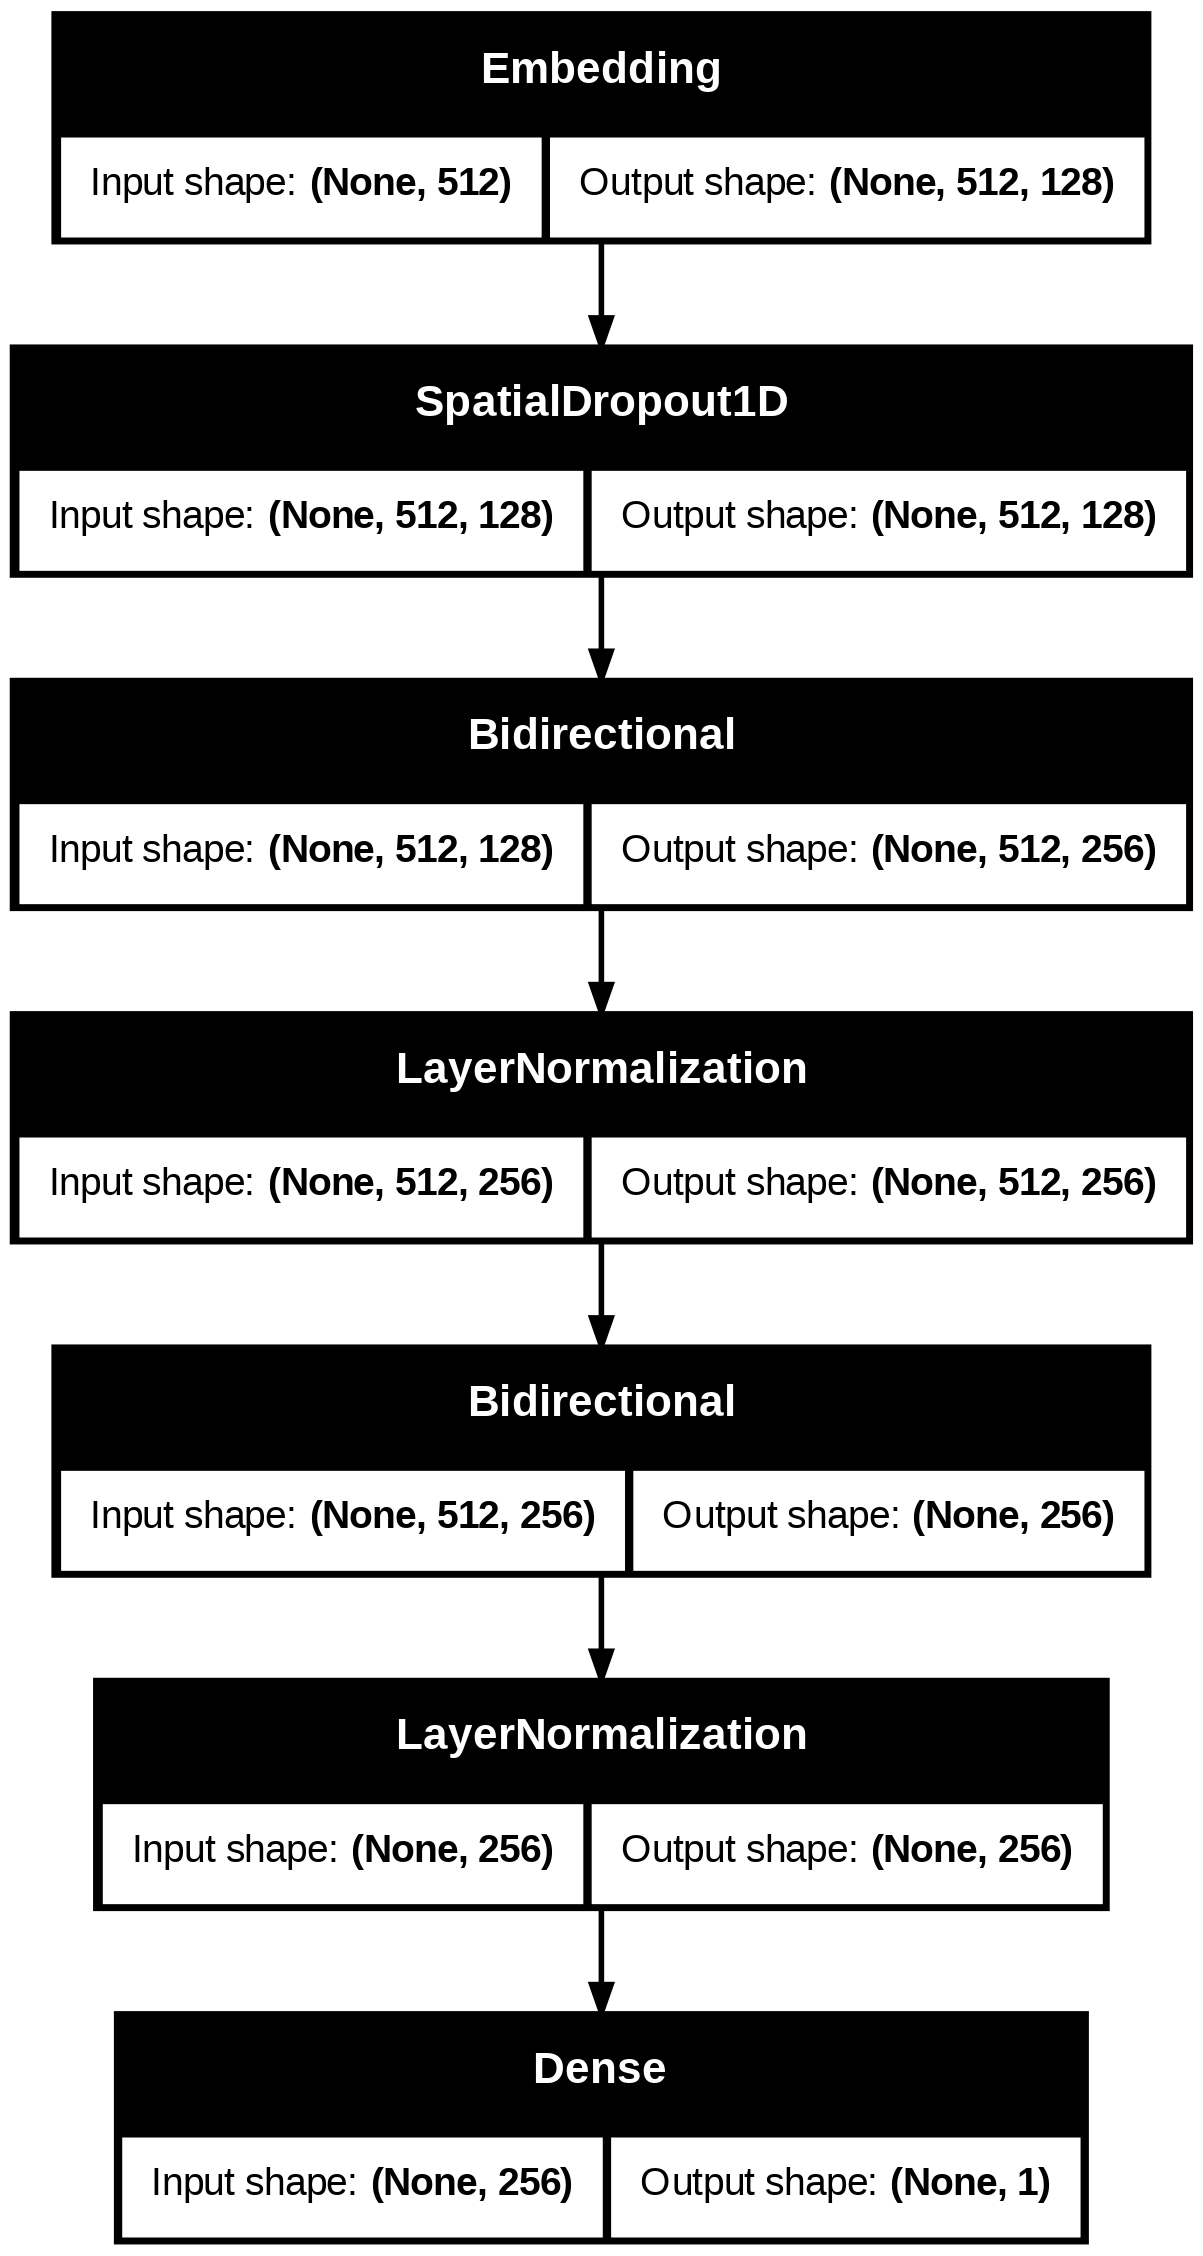

In [ ]:
plot_model(model_lstm_vect, show_shapes=True, to_file=f'drive/MyDrive/Dissertation/Results/{abstract}/{name}/Image/Deep Learning/BiLSTM_multichannel.png')

In [ ]:
results = model_lstm_vect.evaluate(X_test_BILSTM, y_test_BILSTM.values, return_dict=True, verbose=2)
print("==Test metrics==")
for k, v in results.items():
    print(f"{k}: {v*100:.2f}%")

"""
==Test metrics==
accuracy: 98.62%
loss: 5.44%
pr_auc: 98.97%
""";

18/18 - 1s - 34ms/step - accuracy: 0.9388 - loss: 0.4225 - pr_auc: 0.8825
==Test metrics==
accuracy: 93.88%
loss: 42.25%
pr_auc: 88.25%


In [ ]:
y_val_logits_lstm = model_lstm_vect.predict(X_val_BILSTM).ravel()

y_val_pred_lstm = tf.nn.sigmoid(y_val_logits_lstm).numpy()

# 1. Get precision, recall, and thresholds
# y_test_CNN, y_pred_cnn
precision, recall, thresholds = precision_recall_curve(y_val_BILSTM, y_val_pred_lstm)

# 2. Calculate F1-score for each threshold
# F1 = 2 * (precision * recall) / (precision + recall)
f1_scores = (2 * recall * precision) / (recall + precision + 1e-10)

# 3. Find the index of the highest F1-score
best_idx = np.argmax(f1_scores[:-1])
best_threshold = thresholds[best_idx]

print(f"Best Threshold: {best_threshold:.4f}")
print(f"Best F1-Score: {f1_scores[best_idx]:.4f}")
print(f"Predictions generated using {best_threshold:.4f} threshold.")

# y_pred_lstm = (y_val_pred_lstm >= best_threshold).astype(int) # threshold predictions

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step
Best Threshold: 0.7904
Best F1-Score: 0.8667
Predictions generated using 0.7904 threshold.


In [ ]:
y_test_logits = model_lstm_vect.predict(X_test_BILSTM).ravel()
y_test_probs = tf.nn.sigmoid(y_test_logits).numpy()
y_pred_lstm = (y_test_probs >= best_threshold).astype(int)

# y_val_BILSTM -> y_test_BILSTM
# y_val_pred -> y_pred_lstm

18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step


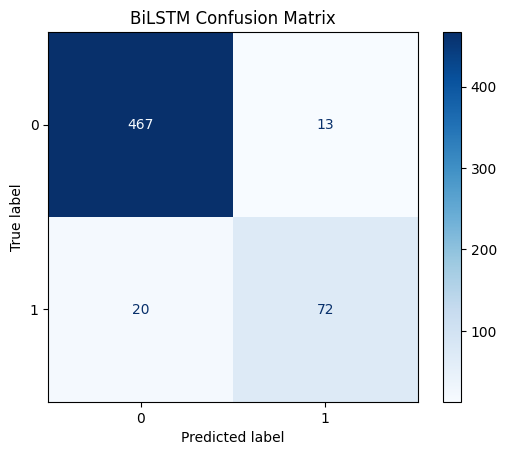

In [ ]:
cm = confusion_matrix(y_test_BILSTM, y_pred_lstm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title(f"BiLSTM Confusion Matrix")

# plt.show()
plt.savefig(fname=f'drive/MyDrive/Dissertation/Results/{abstract}/{name}/Image/Deep Learning/BiLSTM_confusionMatrix.png', format='png')

In [ ]:
names: list   = ['Ham', 'Spam']
report = classification_report(y_test_BILSTM, y_pred_lstm, target_names=names, output_dict=True)
lstm_dataframe = pd.DataFrame(report).transpose()
lstm_dataframe

,precision,recall,f1-score,support
Ham,0.958932,0.972917,0.965874,480.000000
Spam,0.847059,0.782609,0.813559,92.000000
accuracy,0.942308,0.942308,0.942308,0.942308
macro avg,0.902996,0.877763,0.889717,572.000000
weighted avg,0.940939,0.942308,0.941376,572.000000


In [ ]:
# Save the classification report to a CSV file
lstm_dataframe.to_csv(f'drive/MyDrive/Dissertation/Results/{abstract}/{name}/Results/classification_report_BiLSTM.csv', index=True)

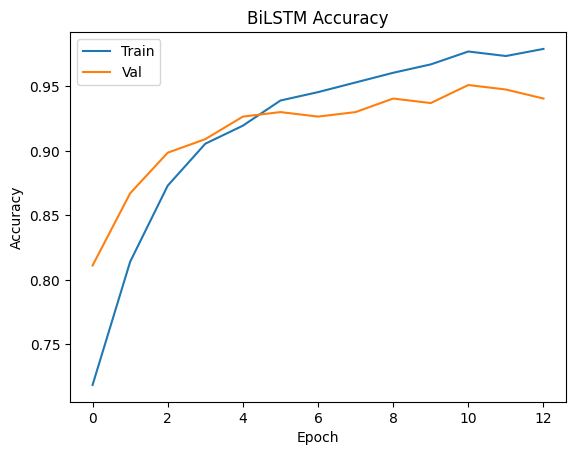

In [ ]:
# summarize history for accuracy
plt.plot(history_lstm.history['accuracy'])
plt.plot(history_lstm.history['val_accuracy'])
plt.title('BiLSTM Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Val'], loc='upper left')
plt.savefig(f'drive/MyDrive/Dissertation/Results/{abstract}/{name}/Image/Deep Learning/BiLSTM_accuracy.png', format='png')
# plt.show()

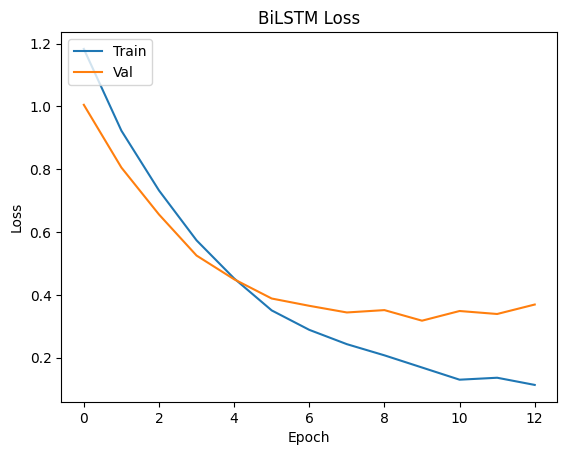

In [ ]:
plt.plot(history_lstm.history['loss'])
plt.plot(history_lstm.history['val_loss'])
plt.title('BiLSTM Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Val'], loc='upper left')
plt.savefig(f'drive/MyDrive/Dissertation/Results/{abstract}/{name}/Image/Deep Learning/BiLSTM_loss.png', format='png')

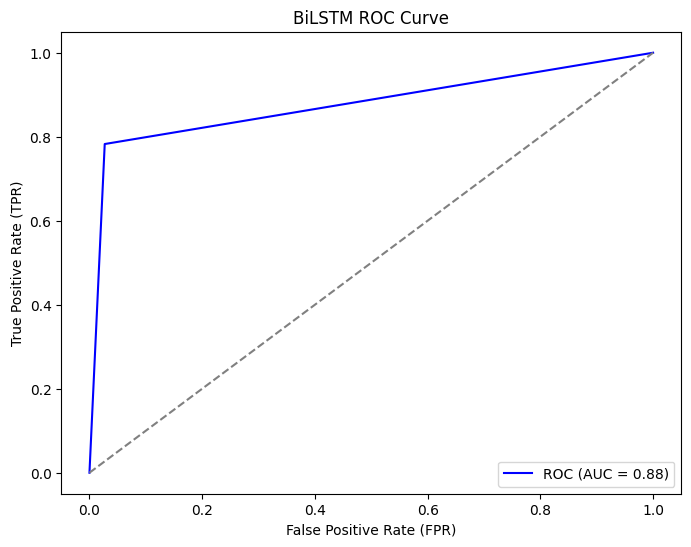

In [ ]:
# AUC SCORE
auc_score = roc_auc_score(y_test_BILSTM, y_pred_lstm)

# ROC curve (for plotting)
fpr, tpr, _ = roc_curve(y_test_BILSTM, y_pred_lstm)
roc_auc = auc(fpr, tpr)

# Plotting the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f'ROC (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Diagonal line (random classifier)
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title(f'BiLSTM ROC Curve')
plt.legend(loc='lower right')
plt.savefig(fname=f'drive/MyDrive/Dissertation/Results/{abstract}/{name}/Image/Deep Learning/BiLSTM_ROC.png', format='png', dpi=300, bbox_inches="tight")

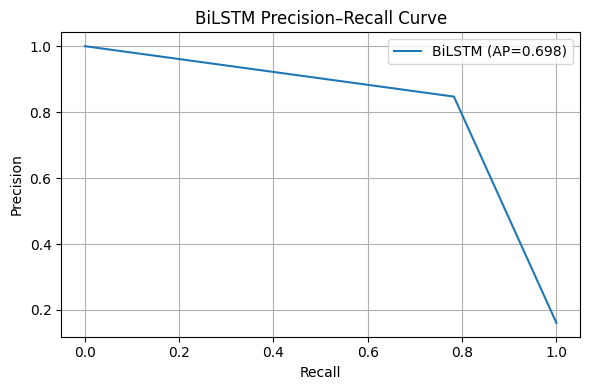

In [ ]:
# y_true = np.asarray(y_test_).ravel()

plt.figure(figsize=(6,4))

scores = model_lstm_vect.predict(X_val_BILSTM, verbose=0).ravel()  # probabilities
precision, recall, _ = precision_recall_curve(y_test_BILSTM, y_pred_lstm)
ap = np.round(average_precision_score(y_test_BILSTM, y_pred_lstm), 3)  # PR-AUC
plt.plot(recall, precision, label=f"BiLSTM (AP={ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("BiLSTM Precision–Recall Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(f'drive/MyDrive/Dissertation/Results/{abstract}/{name}/Image/Deep Learning/BiLSTM_pr.png', format='png', dpi=300, bbox_inches="tight")
# plt.show()

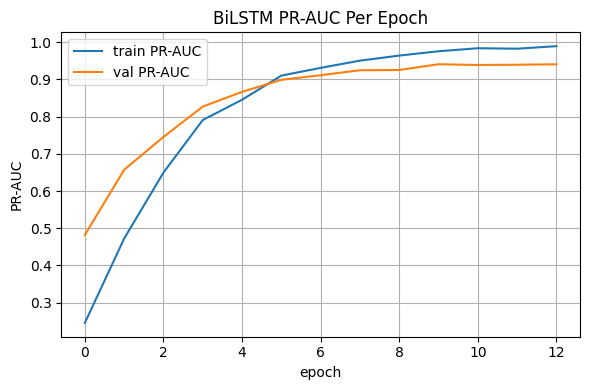

In [ ]:
plt.figure(figsize=(6,4))
plt.plot(history_lstm.history['pr_auc'], label='train PR-AUC')
plt.plot(history_lstm.history['val_pr_auc'], label='val PR-AUC')
plt.xlabel("epoch")
plt.ylabel("PR-AUC")
plt.title("BiLSTM PR-AUC Per Epoch")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(f'drive/MyDrive/Dissertation/Results/{abstract}/{name}/Image/Deep Learning/BiLSTM_pr_auc_epoch.png', format='png')
# plt.show()

In [ ]:
# Use consistent variable
accuracy = np.round(accuracy_score(y_test_BILSTM, y_pred_lstm), 3)
precision = np.round(precision_score(y_test_BILSTM, y_pred_lstm), 3)
recall = np.round(recall_score(y_test_BILSTM, y_pred_lstm), 3)
f1 = np.round(f1_score(y_test_BILSTM, y_pred_lstm), 3)
threshold = np.round(best_threshold, 3)

cm = confusion_matrix(y_test_BILSTM, y_pred_lstm)
tn, fp, fn, tp = cm.ravel()

print("==BiLSTM Metrics==")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)
print()
print("True Positive:", tp)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Negative:", tn)

==BiLSTM Metrics==
Accuracy: 0.942
Precision: 0.847
Recall: 0.783
F1-Score: 0.814

True Positive: 72
False Positive: 13
False Negative: 20
True Negative: 467


In [ ]:
results_dp.loc[len(results_dp)] = ["BiLSTM",
                   round(timer_callback.total_seconds/60, 2),
                   accuracy, precision, recall, f1, threshold, auc_score,
                   ap, tp, tn, fp, fn]

## Saving models

In [ ]:
results_dp

,Model,Time,Accuracy,Precision,Recall,F1-Score,Threshold,AUC,PR-AUC,TP,TN,FP,FN
0,CNN,0.39,0.970,0.895,0.924,0.909,0.50,0.951540,0.839,85,470,10,7
1,BiLSTM,1.24,0.942,0.847,0.783,0.814,0.79,0.877763,0.698,72,467,13,20


In [ ]:
results_dp.to_csv(f'drive/MyDrive/Dissertation/Results/{abstract}/{name}/Results/deeplearning_metrics.csv', index=False)